# Model A — Reference pix2pix trên Kaggle

**Luồng chính:** Kaggle Input → ghép sketch/ảnh màu → train GAN → lưu checkpoint → sinh ảnh và đánh giá.
Notebook dùng các cặp đầy đủ trong bộ AnimeFaceColorization bạn đã tải và đóng ZIP.
Các cell Markdown giải thích phần code ngay bên dưới.

**Cách chạy**
1. Upload notebook và gắn dataset bằng **Add Input**.
2. Bật GPU. Bật Internet lần đầu để tải weights VGG19/LPIPS nếu chưa có cache.
3. Sửa `DATA_ROOT` ở mục 2: đường dẫn thư mục chứa `sketch/`, `reference/`, hoặc đường dẫn tới file ZIP.
4. Chạy tuần tự. Mặc định train thử 1.000 cặp trong 2 epoch, xuất 8 input × 5 seeds.
5. Sau khi kiểm tra ảnh/loss, đặt `TRAIN_LIMIT=None`, `EPOCHS=30`, dùng `RUN_NAME` mới để train đầy đủ.

Đầu vào là sketch xám và reference RGB; ảnh được đưa về 256×256 trong `[-1,1]`.
Mô hình dùng U-Net + PatchGAN, LSGAN + L1 + VGG19. Reference train là target được crop/flip/TPS.
Các biến thể của cùng ảnh nguồn ở chung split để tránh rò rỉ dữ liệu.

Chọn checkpoint bằng validation. PSNR/SSIM/LPIPS và diversity tính từ ảnh PNG đã lưu.
FID/KID/FD-DINOv2 và user study thuộc bộ đánh giá chung của nhóm. Chưa có kết quả train thật được xác nhận.


## 1. Thư viện
Dùng PyTorch, torchvision và các thư viện ảnh có sẵn trên Kaggle.
LPIPS được cài khi chạy phần đánh giá nếu chưa có. VGG19 tải weights ở phần loss.
Cell này in thiết bị đang sử dụng; chọn GPU trước khi train thật.


In [1]:
import csv
import importlib.util
import subprocess
import sys
import zipfile
import hashlib
import json
import math
import os
import random
import re
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from torchvision.transforms import functional as TF
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0], '| torch:', torch.__version__,
      '| torchvision:', torchvision.__version__, '| device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU: chỉ nên smoke test; bật GPU trước khi train thật.')


Python: 3.13.15 | torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128 | device: cuda
GPU: Tesla T4


## 2. Cấu hình
Sửa **`DATA_ROOT`** theo đường dẫn trong thanh **Input** của Kaggle.

- Nếu đã giải nén: `/kaggle/input/ten-dataset` chứa trực tiếp `sketch/` và `reference/`.
- Nếu còn file ZIP: `/kaggle/input/ten-dataset/AnimeFaceColorization_paired.zip`.

ZIP được giải nén một lần vào `/kaggle/working`, dùng lại trong cùng phiên.
`RUN_NAME` đặt tên thư mục kết quả. `TRAIN_LIMIT`, `EPOCHS`, `BATCH_SIZE` điều khiển lần train thử.
`RESUME_PATH` để trống khi train mới, hoặc trỏ đến `last.pt` khi tiếp tục phiên trước.


In [2]:
IMAGE_SIZE = 256  # Cố định theo thiết kế Model A.

@dataclass
class Config:
    # Thường chỉ cần sửa DATA_ROOT, RUN_NAME, EPOCHS và BATCH_SIZE.
    DATA_ROOT: str = '/kaggle/input/datasets/dangnamcuong/genai-anh'  # Sửa theo đường dẫn Add Input.
    WORK_ROOT: str = '/kaggle/working'
    RUN_NAME: str = 'model_a_smoke'
    SEED: int = 5413
    TRAIN_LIMIT: int | None = 1000
    EPOCHS: int = 2
    BATCH_SIZE: int = 4
    NUM_WORKERS: int = 2  # Dùng 0 khi debug DataLoader.
    LR: float = 2e-4
    LAMBDA_L1: float = 100.0
    LAMBDA_PERCEPTUAL: float = 10.0
    NGF: int = 64
    NDF: int = 64
    AMP: bool = True
    CHECKPOINT_MINUTES: int = 30
    PATIENCE: int = 8
    RESUME_PATH: str = ''
    DO_TRAIN: bool = True
    USE_LPIPS: bool = True
    SAMPLE_SEEDS: tuple = (11, 22, 33, 44, 55)
    # Xuất thử 8 input. Đặt None khi đánh giá toàn bộ test.
    EXPORT_TEST_LIMIT: int | None = 8
    EVAL_MODE: str = 'self'  # 'self' hoặc 'cross'

cfg = Config()
assert cfg.EPOCHS >= 1 and cfg.BATCH_SIZE >= 1
RUN = Path(cfg.WORK_ROOT) / cfg.RUN_NAME
for folder in ['checkpoints', 'splits', 'previews', 'results', 'outputs']:
    (RUN / folder).mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def stable_seed(text):
    return int.from_bytes(hashlib.sha256(str(text).encode()).digest()[:4], 'little')

seed_everything(cfg.SEED)
print('Input:', cfg.DATA_ROOT)
print('Output:', RUN)
print(f'Train thử: {cfg.TRAIN_LIMIT} cặp; {cfg.EPOCHS} epoch; batch size {cfg.BATCH_SIZE}')



Input: /kaggle/input/datasets/dangnamcuong/genai-anh
Output: /kaggle/working/model_a_smoke
Train thử: 1000 cặp; 2 epoch; batch size 4


## 3. Ghép cặp và chia dữ liệu
Ghép sketch và ảnh màu theo đường dẫn tương đối trong hai thư mục. Chỉ dùng các cặp đủ cả hai ảnh;
in số lượng thực tế và lưu manifest/splits để ba mô hình dùng chung.

Chia khoảng 80/10/10 theo nhóm ảnh nguồn, seed cố định. Các bản `_augN` đi cùng ảnh gốc.
`AnimeDiffusion_<id>` là nhóm ảnh nguồn; các folder moeimouto là ID nhân vật dùng cho cross-reference.
Đây là split của bộ cặp đã chọn, không phải official test split của AnimeDiffusion.


In [3]:
DATA_ROOT = Path(cfg.DATA_ROOT)
if DATA_ROOT.suffix.lower() == '.zip':
    archive = DATA_ROOT
    archive_key = stable_seed(f'{archive.resolve()}:{archive.stat().st_size}:{archive.stat().st_mtime_ns}')
    DATA_ROOT = Path(cfg.WORK_ROOT)/f'animeface_data_{archive_key}'
    ready = DATA_ROOT/'.ready'
    if not ready.exists():
        print('Đang giải nén dataset vào:', DATA_ROOT)
        with zipfile.ZipFile(archive) as zip_file:
            zip_file.extractall(DATA_ROOT)
        ready.touch()
IMAGE_EXTS = {'.png', '.jpg', '.jpeg', '.webp', '.bmp'}

def image_index(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f'Chưa thấy {folder}. Sửa DATA_ROOT theo đường dẫn Kaggle Input.')
    images = {}
    for path in sorted(folder.rglob('*')):
        if path.suffix.lower() in IMAGE_EXTS:
            key = path.relative_to(folder).with_suffix('').as_posix()
            if key in images:
                raise ValueError(f'Trùng tên ảnh: {key}')
            images[key] = path
    return images

def write_csv(path, rows, fields):
    with Path(path).open('w', newline='', encoding='utf-8') as file:
        writer = csv.DictWriter(file, fieldnames=fields, extrasaction='ignore')
        writer.writeheader()
        writer.writerows(rows)

sketches = image_index(DATA_ROOT / 'sketch')
colors = image_index(DATA_ROOT / 'reference')
paired_keys = sorted(sketches.keys() & colors.keys())
sketch_only = sorted(sketches.keys() - colors.keys())
reference_only = sorted(colors.keys() - sketches.keys())
data_summary = dict(sketch=len(sketches), reference=len(colors), paired=len(paired_keys),
                    sketch_only=len(sketch_only), reference_only=len(reference_only))
print('Dữ liệu đầu vào:', data_summary)
(RUN/'splits/data_summary.json').write_text(json.dumps(data_summary, indent=2), encoding='utf-8')

rows, source_groups = [], {}
for key in paired_keys:
    target_path = colors[key]
    relative = Path(key)
    folder = relative.parts[0]
    is_anime_diffusion = folder.startswith('AnimeDiffusion_')
    base_stem = re.sub(r'_aug\d+$', '', relative.name)
    source_id = folder if is_anime_diffusion else (relative.parent / base_stem).as_posix()
    row = dict(image_id='hf_' + hashlib.sha256(key.encode()).hexdigest()[:16],
               sketch=str(sketches[key]), target=str(target_path),
               character_id='' if is_anime_diffusion else folder)
    rows.append(row)
    source_groups.setdefault(source_id, []).append(row)

groups = sorted(source_groups)
random.Random(cfg.SEED).shuffle(groups)
assert len(groups) >= 3, 'Cần ít nhất 3 nhóm ảnh nguồn để chia train/val/test.'
n_test = n_val = max(1, len(groups) // 10)
for i, group in enumerate(groups):
    split = 'test' if i < n_test else 'val' if i < n_test+n_val else 'train'
    for row in source_groups[group]:
        row['split'] = split

SPLITS = {split: sorted([r for r in rows if r['split'] == split], key=lambda r: r['image_id'])
          for split in ['train', 'val', 'test']}
write_csv(RUN/'splits/manifest.csv', rows, ['image_id','sketch','target','split','character_id'])
for split, subset in SPLITS.items():
    (RUN/f'splits/{split}.txt').write_text('\n'.join(r['image_id'] for r in subset) + '\n')

# IDs sinh từ đường dẫn tương đối: chữ ký giữ nguyên khi đổi vị trí DATA_ROOT.
DATA_SIGNATURE = hashlib.sha256(json.dumps(
    sorted((r['image_id'], r['split']) for r in rows)).encode()).hexdigest()
print('Số cặp:', {split: len(subset) for split, subset in SPLITS.items()})


Dữ liệu đầu vào: {'sketch': 80345, 'reference': 80345, 'paired': 80345, 'sketch_only': 0, 'reference_only': 0}
Số cặp: {'train': 64143, 'val': 7996, 'test': 8206}


## 4. Augmented self-reference: giữ màu, phá căn chỉnh
Target và sketch chỉ resize, không biến dạng độc lập. Reference được lấy từ target,
crop nhẹ, có thể flip rồi TPS (thin-plate spline). TPS dùng lưới điều khiển 3×3 và nội suy
trên lưới nhỏ để giảm CPU; lấy mẫu ảnh với reflection padding để tránh viền đen giả.
Đây là phép biến dạng hình học, không phải đổi hue/saturation.

Validation/test dùng seed từ `image_id`, vì vậy cùng ảnh luôn có cùng reference giữa các lần chạy.
Các seed sinh ảnh chỉ điều khiển dropout, không thay reference. Danh sách cross-reference được xuất ở mục 12.


sketch (1, 256, 256) -1.0 1.0
reference (3, 256, 256) -1.0 1.0
target (3, 256, 256) -1.0 1.0


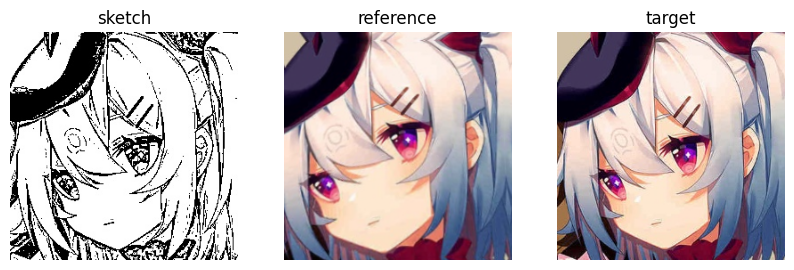

In [4]:
def load_pil(path, mode='RGB'):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert(mode).resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC)

def normalized_tensor(image):
    return TF.to_tensor(image).mul(2).sub(1)

def tps_reference(image, rng):
    size = IMAGE_SIZE
    crop = rng.randint(int(0.85 * size), size)
    top, left = rng.randint(0, size-crop), rng.randint(0, size-crop)
    image = TF.resized_crop(image, top, left, crop, crop, [size, size])
    if rng.random() < 0.5:
        image = TF.hflip(image)
    tensor = normalized_tensor(image)
    # Giải hệ TPS: f(p)=a0+a1*x+a2*y+sum_i w_i U(||p-c_i||²).
    axis = torch.linspace(-1, 1, 3)
    yy, xx = torch.meshgrid(axis, axis, indexing='ij')
    ctrl = torch.stack([xx.flatten(), yy.flatten()], -1)
    displacement = torch.tensor([[rng.uniform(-0.12, 0.12), rng.uniform(-0.12, 0.12)]
                                 for _ in range(9)])
    def radial(r2):
        return r2 * torch.log(r2 + 1e-6)
    kernel = radial(torch.cdist(ctrl, ctrl).square())
    affine = torch.cat([torch.ones(9, 1), ctrl], 1)
    system = torch.zeros(12, 12)
    system[:9, :9] = kernel + 1e-5 * torch.eye(9)
    system[:9, 9:] = affine
    system[9:, :9] = affine.T
    rhs = torch.cat([ctrl + displacement, torch.zeros(3, 2)])
    weights = torch.linalg.solve(system, rhs)
    gy, gx = torch.meshgrid(torch.linspace(-1, 1, 32), torch.linspace(-1, 1, 32), indexing='ij')
    points = torch.stack([gx.flatten(), gy.flatten()], -1)
    basis = torch.cat([radial(torch.cdist(points, ctrl).square()),
                       torch.ones(len(points), 1), points], 1)
    grid = (basis @ weights).view(1, 32, 32, 2).permute(0, 3, 1, 2)
    grid = F.interpolate(grid, size=(size, size), mode='bilinear', align_corners=True)
    return F.grid_sample(tensor[None], grid.permute(0, 2, 3, 1),
                         mode='bilinear', padding_mode='reflection', align_corners=True)[0]

class AnimePairs(Dataset):
    def __init__(self, rows, training=False, cross_refs=None):
        self.rows = rows
        self.training = training
        self.cross_refs = cross_refs

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        r = self.rows[index]
        target_pil = load_pil(r['target'])
        sketch = normalized_tensor(load_pil(r['sketch'], 'L'))
        target = normalized_tensor(target_pil)
        if self.cross_refs is not None:
            reference = normalized_tensor(load_pil(self.cross_refs[r['image_id']]))
        else:
            rng = random if self.training else random.Random(stable_seed(f'{cfg.SEED}:{r["image_id"]}'))
            reference = tps_reference(target_pil, rng)
        # Lượng tử hóa reference như PNG dùng chung: model khác đọc lại đúng cùng input.
        reference = ((reference + 1) * 127.5).round().clamp(0,255).div(127.5).sub(1)
        return dict(sketch=sketch, reference=reference, target=target, image_id=r['image_id'])

def worker_seed(worker_id):
    seed = torch.initial_seed() % (2**32)
    random.seed(seed)
    np.random.seed(seed)
    torch.set_num_threads(1)

train_rows = SPLITS['train'][:cfg.TRAIN_LIMIT] if cfg.TRAIN_LIMIT else SPLITS['train']
train_ds = AnimePairs(train_rows, training=True)
val_ds = AnimePairs(SPLITS['val'])
def loader(dataset, batch_size, generator=None):
    return DataLoader(dataset, batch_size=batch_size,
                      num_workers=cfg.NUM_WORKERS, pin_memory=DEVICE.type == 'cuda',
                      worker_init_fn=worker_seed, generator=generator, drop_last=False)

val_loader = loader(val_ds, cfg.BATCH_SIZE)
example = val_ds[0]
for key in ['sketch', 'reference', 'target']:
    print(key, tuple(example[key].shape), float(example[key].min()), float(example[key].max()))
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, key in zip(axes, ['sketch', 'reference', 'target']):
    image = (example[key] + 1) / 2
    ax.imshow(image.permute(1, 2, 0).squeeze(), cmap='gray' if key == 'sketch' else None)
    ax.set_title(key)
    ax.axis('off')
plt.show()


## 5. Generator U-Net 8 tầng và discriminator PatchGAN
Generator nhận 4 kênh `[sketch; reference]`, nén 256→1 rồi giải mã bằng skip connections.
Ba tầng decoder đầu dùng dropout 0,5. Tầng bottleneck không có BatchNorm nên batch size 1 vẫn chạy được.
Discriminator nhận 4 kênh `[sketch; RGB]`, trả lưới 30×30; mỗi ô có receptive field 70×70.
Không thêm sigmoid vì dùng least-squares GAN.


In [5]:
class Down(nn.Module):
    def __init__(self, cin, cout, norm=True, activate=True):
        super().__init__()
        layers = [nn.LeakyReLU(0.2, inplace=False)] if activate else []
        layers += [nn.Conv2d(cin, cout, 4, 2, 1, bias=not norm)]
        if norm:
            layers += [nn.BatchNorm2d(cout)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

class Up(nn.Module):
    def __init__(self, cin, cout, dropout=False):
        super().__init__()
        layers = [nn.ReLU(inplace=False), nn.ConvTranspose2d(cin, cout, 4, 2, 1, bias=False),
                  nn.BatchNorm2d(cout)]
        if dropout:
            layers += [nn.Dropout(0.5)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

class ReferenceUNet(nn.Module):
    def __init__(self, width=64):
        super().__init__()
        widths = [width, width*2, width*4, width*8, width*8, width*8, width*8, width*8]
        self.down = nn.ModuleList()
        cin = 4
        for i, cout in enumerate(widths):
            self.down.append(Down(cin, cout, norm=i not in (0, 7), activate=i != 0))
            cin = cout
        self.up = nn.ModuleList()
        for i, cout in enumerate(reversed(widths[:-1])):
            self.up.append(Up(cin, cout, dropout=i < 3))
            cin = 2 * cout
        self.final = nn.Sequential(nn.ReLU(), nn.ConvTranspose2d(cin, 3, 4, 2, 1), nn.Tanh())
    def forward(self, sketch, reference):
        x = torch.cat([sketch, reference], 1)
        skips = []
        for layer in self.down:
            x = layer(x)
            skips.append(x)
        for layer, skip in zip(self.up, reversed(skips[:-1])):
            x = torch.cat([layer(x), skip], 1)
        return self.final(x)

class PatchDiscriminator(nn.Module):
    def __init__(self, width=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(4, width, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(width, width*2, 4, 2, 1, bias=False), nn.BatchNorm2d(width*2), nn.LeakyReLU(0.2),
            nn.Conv2d(width*2, width*4, 4, 2, 1, bias=False), nn.BatchNorm2d(width*4), nn.LeakyReLU(0.2),
            nn.Conv2d(width*4, width*8, 4, 1, 1, bias=False), nn.BatchNorm2d(width*8), nn.LeakyReLU(0.2),
            nn.Conv2d(width*8, 1, 4, 1, 1))
    def forward(self, sketch, color):
        return self.net(torch.cat([sketch, color], 1))

def init_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1, 0.02)
        nn.init.zeros_(module.bias)

G = ReferenceUNet(cfg.NGF).to(DEVICE)
D = PatchDiscriminator(cfg.NDF).to(DEVICE)
G.apply(init_weights)
D.apply(init_weights)
print('G:', sum(p.numel() for p in G.parameters()) / 1e6, 'M parameters')
print('D:', sum(p.numel() for p in D.parameters()) / 1e6, 'M parameters')


G: 54.415555 M parameters
D: 2.766657 M parameters


## 6. Hàm mất mát và mixed precision
Discriminator: `0.5 × [MSE(D(real),1) + MSE(D(fake),0)]`.
Generator: `MSE(D(fake),1) + 100×L1(fake,target) + 10×perceptual`.
VGG19 đã pretrained, đóng băng tham số nhưng vẫn truyền gradient về ảnh giả. Ảnh được đổi về
`[0,1]` rồi chuẩn hóa ImageNet; lấy trung bình loss tại relu1_2, relu2_2, relu3_4, relu4_4.
Đây là lựa chọn chuẩn hóa loss cụ thể của notebook; hệ số 10 cần kiểm chứng trên validation.
AMP chỉ bật trên CUDA; dùng hai GradScaler riêng cho hai optimizer.


In [6]:
class VGGPerceptual(nn.Module):
    def __init__(self):
        super().__init__()
        features = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1).features
        self.features = features[:27].eval().requires_grad_(False)
        self.register_buffer('mean', torch.tensor([.485, .456, .406])[None, :, None, None])
        self.register_buffer('std', torch.tensor([.229, .224, .225])[None, :, None, None])
        self.layers = {3, 8, 17, 26}
    def encode(self, image):
        x = ((image + 1) / 2 - self.mean) / self.std
        values = []
        for i, layer in enumerate(self.features):
            x = layer(x)
            if i in self.layers:
                values.append(x)
        return values
    def forward(self, fake, target):
        predicted = self.encode(fake)
        with torch.no_grad():
            actual = self.encode(target)
        return sum(F.l1_loss(a, b) for a, b in zip(predicted, actual)) / len(actual)

perceptual = VGGPerceptual().to(DEVICE) if cfg.LAMBDA_PERCEPTUAL > 0 else None
opt_g = torch.optim.Adam(G.parameters(), lr=cfg.LR, betas=(.5, .999))
opt_d = torch.optim.Adam(D.parameters(), lr=cfg.LR, betas=(.5, .999))
AMP_ENABLED = cfg.AMP and DEVICE.type == 'cuda'
scaler_g = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
scaler_d = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
def amp_context():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED)

def train_step(batch):
    G.train(); D.train()
    s, r, y = [batch[k].to(DEVICE, non_blocking=True) for k in ['sketch', 'reference', 'target']]
    # Một lần chạy G; nhánh D dùng detach để không thay đổi G.
    opt_g.zero_grad(set_to_none=True)
    with amp_context():
        fake = G(s, r)
    D.requires_grad_(True)
    opt_d.zero_grad(set_to_none=True)
    with amp_context():
        real_score, fake_score = D(s, y), D(s, fake.detach())
        loss_d = .5 * (F.mse_loss(real_score, torch.ones_like(real_score)) +
                        F.mse_loss(fake_score, torch.zeros_like(fake_score)))
    if not torch.isfinite(loss_d):
        raise FloatingPointError('D loss không hữu hạn; dừng để tránh ghi đè checkpoint tốt.')
    scaler_d.scale(loss_d).backward()
    scaler_d.step(opt_d)
    scaler_d.update()
    # Đóng băng D và running statistics khi tối ưu G; gradient vẫn đi qua D về fake.
    D.requires_grad_(False)
    D.eval()
    with amp_context():
        score = D(s, fake)
        adversarial = F.mse_loss(score, torch.ones_like(score))
        l1 = F.l1_loss(fake, y)
    # VGG float32 giúp ổn định perceptual loss, vẫn giữ gradient về G.
    p = perceptual(fake.float(), y.float()) if perceptual is not None else fake.new_zeros(())
    loss_g = adversarial.float() + cfg.LAMBDA_L1 * l1.float() + cfg.LAMBDA_PERCEPTUAL * p
    if not torch.isfinite(loss_g):
        raise FloatingPointError('G loss không hữu hạn.')
    scaler_g.scale(loss_g).backward()
    scaler_g.step(opt_g)
    scaler_g.update()
    D.requires_grad_(True)
    return {k: float(v.detach()) for k, v in
            dict(g=loss_g, d=loss_d, l1=l1, perceptual=p, adversarial=adversarial).items()}


Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:02<00:00, 242MB/s]


## 7. Validation và ảnh theo dõi
Chọn checkpoint bằng **validation L1** với dropout tắt, không dùng test để chọn mô hình.
PSNR tính trên `[0,1]`, trung bình theo ảnh. Validation chỉ là một quy tắc chọn checkpoint;
các ảnh/metric test nhiều seed được xuất sau. Ảnh grid gồm sketch, reference, prediction, target.


In [7]:
@torch.inference_mode()
def validate(epoch):
    G.eval()
    totals = {'l1': 0., 'psnr': 0.}
    count = 0
    for batch_index, batch in enumerate(val_loader):
        s, r, y = [batch[k].to(DEVICE) for k in ['sketch', 'reference', 'target']]
        with amp_context():
            pred = G(s, r)
        pred = pred.float()
        n = len(y)
        totals['l1'] += F.l1_loss(pred, y, reduction='none').mean((1,2,3)).sum().item()
        mse = ((pred-y)/2).square().mean((1,2,3)).clamp_min(1e-12)
        totals['psnr'] += (-10*torch.log10(mse)).sum().item()
        count += n
        if batch_index == 0:
            images = torch.stack([s[:4].expand(-1,3,-1,-1), r[:4], pred[:4], y[:4]], 1)
            grid = make_grid((images.flatten(0,1).cpu()+1)/2, nrow=4)
            save_image(grid, RUN / f'previews/epoch_{epoch:03d}.png')
    return {key: value/count for key, value in totals.items()}


## 8. Checkpoint và resume qua phiên Kaggle
Lưu G, D, hai optimizer, hai scaler, epoch/batch tiếp theo, best loss, history và trạng thái RNG.
File ghi tạm rồi thay thế để giảm nguy cơ checkpoint hỏng nếu bị ngắt lúc ghi.
Resume kiểm tra manifest/splits, batch size, train limit và seed; `EPOCHS` có thể tăng.
State dict kiểm tra kiến trúc khi load. Optimizer khôi phục learning rate từ checkpoint;
`AMP` và `NUM_WORKERS` không bị khóa, nhưng thay chúng có thể làm kết quả tiếp tục khác từng bit.

Với `NUM_WORKERS=0`, resume có thể phục hồi chính xác chuỗi augmentation/dropout trong epoch.
Với nhiều workers, thứ tự ảnh được giữ nhưng trạng thái augmentation đã prefetch không được khôi phục
chính xác; resume vẫn hợp lệ để tiếp tục train, không bảo đảm giống từng bit.
Checkpoint `.pt` dùng pickle: chỉ load checkpoint do bạn/nhóm tạo và tin cậy.

Nên giữ cả `last.pt` và `best.pt` trong output Kaggle. Nếu chỉ còn `last.pt`, notebook vẫn tiếp tục
được; khi chưa có best mới, suy luận dùng checkpoint hiện có và ghi `last_available` trong kết quả.
Scaler AMP của phiên không dùng mixed precision có thể rỗng; phiên AMP mới sẽ tạo scaler mới.


In [8]:
components = dict(G=G, D=D, opt_g=opt_g, opt_d=opt_d, scaler_g=scaler_g, scaler_d=scaler_d)

state = dict(epoch=0, next_batch=0, global_step=0, best_val=float('inf'),
             bad_epochs=0, history=[], epoch_sum={}, epoch_seen=0)

def capture_rng():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)

def restore_rng(rng):
    random.setstate(rng['python'])
    np.random.set_state(rng['numpy'])
    torch.set_rng_state(rng['torch'].cpu())
    if torch.cuda.is_available() and rng['cuda'] is not None:
        torch.cuda.set_rng_state_all([x.cpu() for x in rng['cuda']])

def save_checkpoint(filename):
    path = RUN / 'checkpoints' / filename
    payload = {name: component.state_dict() for name,component in components.items()}
    payload.update(state=state, rng=capture_rng(), config=asdict(cfg), data_signature=DATA_SIGNATURE)
    temporary = path.with_suffix('.tmp')
    torch.save(payload, temporary)
    os.replace(temporary, path)

if cfg.RESUME_PATH:
    checkpoint = torch.load(cfg.RESUME_PATH, map_location='cpu', weights_only=False)
    assert checkpoint['data_signature'] == DATA_SIGNATURE, 'Manifest/splits đã thay đổi.'
    # Giữ cách chia batch và thứ tự dữ liệu để tiếp tục đúng vị trí.
    required_same = ['BATCH_SIZE', 'TRAIN_LIMIT', 'SEED']
    for key in required_same:
        assert checkpoint['config'][key] == asdict(cfg)[key], f'Resume cần giữ {key}.'
    for name,component in components.items():
        # Không dùng AMP ở phiên cũ => scaler state rỗng; phiên mới khởi tạo scaler mới.
        if name.startswith('scaler_') and not checkpoint[name]:
            continue
        component.load_state_dict(checkpoint[name])
    state = checkpoint['state']
    restore_rng(checkpoint['rng'])
    # Khi resume ở RUN mới, giữ bản best cũ thay vì để cell inference dùng nhầm last.
    previous_best = Path(cfg.RESUME_PATH).with_name('best.pt')
    if previous_best.is_file() and previous_best.resolve() != (RUN/'checkpoints/best.pt').resolve():
        import shutil
        shutil.copy2(previous_best, RUN/'checkpoints/best.pt')
    print('Resume:', {k:v for k,v in state.items() if k not in ['history', 'epoch_sum']})
else:
    assert not (RUN/'checkpoints/last.pt').exists(), \
        'RUN đã có last.pt. Đặt RESUME_PATH hoặc dùng RUN_NAME mới để tránh ghi đè.'

(RUN/'config.json').write_text(json.dumps(asdict(cfg), indent=2, ensure_ascii=False), encoding='utf-8')
environment = dict(python=sys.version, torch=torch.__version__, torchvision=torchvision.__version__,
                   numpy=np.__version__, cuda=torch.version.cuda,
                   gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'cpu')
(RUN/'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')


187

## 9. Huấn luyện
Mỗi epoch xáo trộn train bằng seed riêng cố định. Resume bắt đầu ở batch kế tiếp, không lặp lại
các batch đã hoàn thành. Lưu `last.pt` mỗi 30 phút và cuối epoch; `best.pt` khi validation tốt hơn.
Learning rate cố định theo cấu hình dự án. Early stopping dựa trên số epoch validation không cải thiện.
Nếu chủ động ngắt cell bằng nút stop hoặc phiên bị kill đột ngột, tiếp tục từ checkpoint đã ghi trước đó.
Không ghi checkpoint trong lúc một optimizer step mới hoàn thành một phần.


In [9]:
if cfg.DO_TRAIN:
    last_save = time.monotonic()
    for epoch in range(state['epoch'], cfg.EPOCHS):
        if state['bad_epochs'] >= cfg.PATIENCE:
            print('Đã đạt early stopping.'); break
        start_batch = state['next_batch']
        order = torch.randperm(len(train_ds), generator=torch.Generator().manual_seed(cfg.SEED+epoch)).tolist()
        offset = start_batch * cfg.BATCH_SIZE
        remaining = torch.utils.data.Subset(train_ds, order[offset:])
        train_loader = loader(remaining, cfg.BATCH_SIZE,
                              generator=torch.Generator().manual_seed(cfg.SEED+epoch))
        running, seen = dict(state['epoch_sum']), state['epoch_seen']
        progress = tqdm(train_loader, desc=f'Epoch {epoch+1}/{cfg.EPOCHS}',
                        initial=start_batch, total=math.ceil(len(train_ds)/cfg.BATCH_SIZE))
        for batch_index, batch in enumerate(progress, start=start_batch):
            values = train_step(batch)
            n = len(batch['target'])
            seen += n
            for key, value in values.items():
                running[key] = running.get(key, 0.) + value*n
            # Đánh dấu hoàn thành sau cả hai optimizer.
            state.update(epoch=epoch, next_batch=batch_index+1,
                         global_step=state['global_step']+1,
                         epoch_sum=running, epoch_seen=seen)
            progress.set_postfix(g=f'{values["g"]:.3f}', d=f'{values["d"]:.3f}', l1=f'{values["l1"]:.3f}')
            if time.monotonic()-last_save >= cfg.CHECKPOINT_MINUTES*60:
                save_checkpoint('last.pt')
                last_save = time.monotonic()
        saved_rng = capture_rng()
        val = validate(epoch+1)
        restore_rng(saved_rng)
        record = dict(epoch=epoch+1, step=state['global_step'],
                      **{f'train_{k}':v/seen for k,v in running.items()},
                      **{f'val_{k}':v for k,v in val.items()})
        state['history'].append(record)
        improved = val['l1'] < state['best_val']
        state['bad_epochs'] = 0 if improved else state['bad_epochs']+1
        if improved:
            state['best_val'] = val['l1']
        state.update(epoch=epoch+1, next_batch=0, epoch_sum={}, epoch_seen=0)
        if improved:
            save_checkpoint('best.pt')
        save_checkpoint('last.pt')
        last_save = time.monotonic()
        write_csv(RUN/'results/history.csv', state['history'], list(record))
        print(record)
else:
    print('DO_TRAIN=False: bỏ qua huấn luyện.')


Epoch 1/2:   0%|          | 0/250 [00:00<?, ?it/s]

{'epoch': 1, 'step': 250, 'train_g': 37.907420272827146, 'train_d': 0.5355014675259591, 'train_l1': 0.29557944667339325, 'train_perceptual': 0.7875348095893859, 'train_adversarial': 0.4741273509860039, 'val_l1': 0.2658725815334578, 'val_psnr': 15.101981999815672}


Epoch 2/2:   0%|          | 0/250 [00:00<?, ?it/s]

{'epoch': 2, 'step': 500, 'train_g': 32.142471206665036, 'train_d': 0.2725163875818253, 'train_l1': 0.24592891800403596, 'train_perceptual': 0.7224928536415101, 'train_adversarial': 0.32465092930197714, 'val_l1': 0.2249251982759034, 'val_psnr': 16.324906561003736}


## 10. Đọc đường học và ảnh validation
L1 validation giảm thường cho thấy màu gần target hơn, nhưng không chứng minh reference khác tư thế đã được dùng đúng.
GAN loss dao động là bình thường; luôn nhìn ảnh. Ảnh nâu/xám, lặp texture hoặc bỏ màu reference cần xem lại
dữ liệu, augmentation và loss trước khi tăng số epoch.


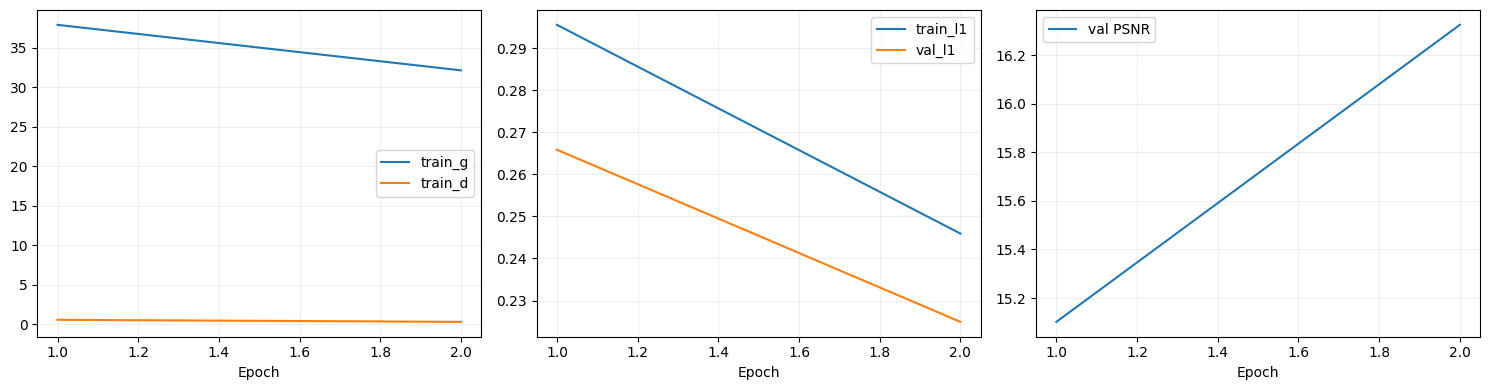

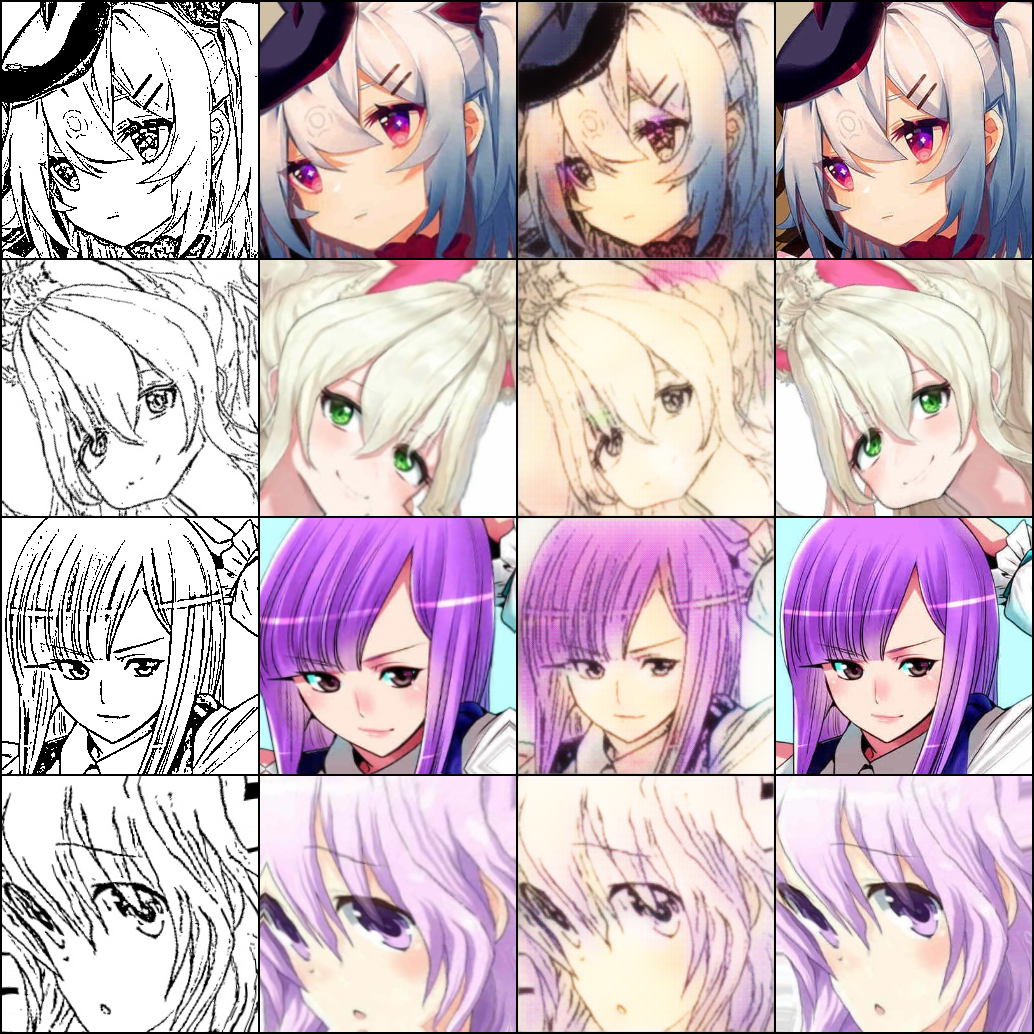

In [10]:
if state['history']:
    history = state['history']
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    epochs = [r['epoch'] for r in history]
    for key in ['train_g', 'train_d']:
        axes[0].plot(epochs, [r[key] for r in history], label=key)
    for key in ['train_l1', 'val_l1']:
        axes[1].plot(epochs, [r[key] for r in history], label=key)
    axes[2].plot(epochs, [r['val_psnr'] for r in history], label='val PSNR')
    for ax in axes:
        ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
    plt.tight_layout(); plt.savefig(RUN/'results/learning_curves.png'); plt.show()
    preview = RUN / f'previews/epoch_{history[-1]["epoch"]:03d}.png'
    if preview.is_file():
        display(Image.open(preview))
else:
    print('Chưa có epoch hoàn thành.')


## 11. Interface chung `Colorizer` và thử ảnh riêng
Ưu tiên `best.pt` sau validation. Nếu chỉ có checkpoint cuối, dùng nó và ghi rõ `last_available`. Khi lấy mẫu, chỉ bật lớp **Dropout**, còn BatchNorm vẫn eval để không
thay đổi running statistics. `colorize()` dùng seed cục bộ, không làm đổi RNG của bên ngoài.
Lớp này dành cho suy luận; `train_step()` tự gọi lại `G.train()` khi huấn luyện.
`steps` giữ để tương thích interface nhóm; GAN chỉ có một lượt generator nên không dùng tham số này.
Với batch, seed áp dụng cho cả batch; bộ xuất bên dưới chạy từng ảnh để kết quả không phụ thuộc batch size.


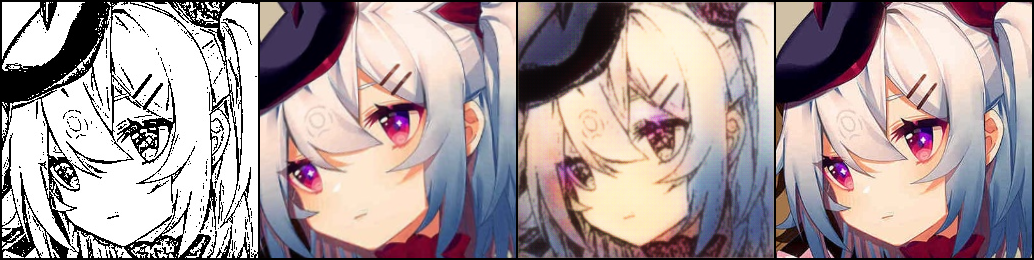

In [11]:
best_path = RUN/'checkpoints/best.pt'
if not best_path.is_file():
    last_path = RUN/'checkpoints/last.pt'
    best_path = last_path if last_path.is_file() else Path(cfg.RESUME_PATH)
    if not best_path.is_file():
        raise FileNotFoundError('Chưa có checkpoint. Train ít nhất một epoch hoặc đặt RESUME_PATH.')
    print('Không có best.pt; dùng checkpoint hiện có:', best_path)
checkpoint_selection = 'best' if best_path.name == 'best.pt' else 'last_available' 
best = torch.load(best_path, map_location='cpu', weights_only=False)
G.load_state_dict(best['G'])
G.eval()
del best

class Colorizer:
    def __init__(self, generator):
        self.generator = generator

    @torch.inference_mode()
    def colorize(self, sketch, reference, seed, steps=None):
        # Colorizer là lớp suy luận: BatchNorm luôn eval, chỉ Dropout được bật để lấy mẫu.
        self.generator.eval()
        for module in self.generator.modules():
            if isinstance(module, nn.Dropout):
                module.train()
        devices = list(range(torch.cuda.device_count())) if DEVICE.type == 'cuda' else []
        with torch.random.fork_rng(devices=devices):
            torch.manual_seed(seed)
            with amp_context():
                out = self.generator(sketch.to(DEVICE), reference.to(DEVICE))
        return out.float()

colorizer = Colorizer(G)
item = val_ds[0]
pred = colorizer.colorize(item['sketch'][None], item['reference'][None], cfg.SAMPLE_SEEDS[0])
grid = make_grid(torch.cat([item['sketch'][None].expand(-1,3,-1,-1), item['reference'][None],
                           pred.cpu(), item['target'][None]]).add(1).div(2), nrow=4)
display(TF.to_pil_image(grid))

def colorize_files(sketch_path, reference_path, output_path, seed=11):
    sketch = normalized_tensor(load_pil(sketch_path, 'L'))[None]
    reference = normalized_tensor(load_pil(reference_path))[None]
    prediction = colorizer.colorize(sketch, reference, seed)[0].cpu()
    path = Path(output_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    save_image((prediction+1)/2, path)
    return path

# Bỏ dấu # và sửa đường dẫn để thử ảnh của bạn:
# colorize_files('/kaggle/input/my-images/sketch.png',
#                '/kaggle/input/my-images/reference.png', RUN/'my_result.png')


## 12. Xuất ảnh self-reference hoặc cross-reference
Self-reference dùng target đã biến dạng. Cross-reference tự chọn ảnh **khác** của cùng nhân vật
trong test split; các folder `AnimeDiffusion_<id>` không được coi là nhân vật.
Nhân vật chỉ có một ảnh test sẽ không có cặp cross-reference.

Chọn `EVAL_MODE='self'` hoặc `'cross'`, đặt `EXPORT_TEST_LIMIT=None` để xuất toàn bộ test.
Mặc định xuất 8 input để kiểm tra nhanh kết quả; đặt None khi chạy bảng đánh giá cuối.
Mỗi input có 5 PNG theo 5 seeds. Xuất kèm sketch/reference/target thực sự đã dùng để chia sẻ với nhóm.


In [12]:
# Chỉ lấy ảnh khác trong cùng test split và cùng folder nhân vật.
characters = {}
for row in SPLITS['test']:
    if row['character_id']:
        characters.setdefault(row['character_id'], []).append(row)
cross_refs = {}
for members in characters.values():
    if len(members) > 1:
        for i, row in enumerate(members):
            cross_refs[row['image_id']] = members[(i+1) % len(members)]['target']
write_csv(RUN/'splits/cross_ref_pairs.csv',
          [dict(image_id=k, reference=v) for k,v in sorted(cross_refs.items())], ['image_id','reference'])
print('Test inputs:', len(SPLITS['test']), '| Cặp cross-reference hợp lệ:', len(cross_refs))

assert cfg.EVAL_MODE in {'self','cross'}
export_rows = SPLITS['test'] if cfg.EVAL_MODE == 'self' else [r for r in SPLITS['test'] if r['image_id'] in cross_refs]
if cfg.EXPORT_TEST_LIMIT is not None:
    export_rows = export_rows[:cfg.EXPORT_TEST_LIMIT]
export_ds = AnimePairs(export_rows, cross_refs=cross_refs if cfg.EVAL_MODE == 'cross' else None)
OUTPUT_DIR = RUN/'outputs/model_a'/cfg.EVAL_MODE
INPUT_DIR = RUN/'outputs/shared_inputs'/cfg.EVAL_MODE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DIR.mkdir(parents=True, exist_ok=True)
export_records = []
for item in tqdm(export_ds, desc=f'Export {cfg.EVAL_MODE}'):
    image_id = item['image_id']
    for key in ['sketch','reference','target']:
        save_image((item[key]+1)/2, INPUT_DIR/f'{image_id}_{key}.png')
    for seed in cfg.SAMPLE_SEEDS:
        prediction = colorizer.colorize(item['sketch'][None], item['reference'][None], seed)[0].cpu()
        path = OUTPUT_DIR/f'{image_id}_s{seed}.png'
        save_image((prediction+1)/2, path)
        export_records.append(dict(image_id=image_id, seed=seed, output=str(path),
                                   target=str(INPUT_DIR/f'{image_id}_target.png'),
                                   reference=str(INPUT_DIR/f'{image_id}_reference.png')))
write_csv(RUN/f'results/exports_{cfg.EVAL_MODE}.csv', export_records,
          ['image_id','seed','output','target','reference'])
print(f'Đã xuất {len(export_rows)} input × {len(cfg.SAMPLE_SEEDS)} seeds = {len(export_records)} PNG.')
if not export_rows:
    print('Chưa xuất ảnh: đặt EXPORT_TEST_LIMIT hoặc bổ sung test/cross-reference rồi chạy lại cell này.')


Test inputs: 8206 | Cặp cross-reference hợp lệ: 1352


Export self:   0%|          | 0/8 [00:00<?, ?it/s]

Đã xuất 8 input × 5 seeds = 40 PNG.


## 13. Đánh giá từ PNG đã lưu
Self-reference: PSNR, SSIM và LPIPS tới target cho **mọi seed**, báo trung bình, không chọn best-of-5.
Diversity: LPIPS trung bình trên tất cả 10 cặp trong 5 mẫu của cùng input.
Cross-reference chỉ báo diversity ở đây, không dùng PSNR/SSIM/LPIPS-to-target làm fidelity.
LPIPS cần weights pretrained; nếu tắt, CSV ghi `null`, không giả điểm 0.

Các chỉ số paired chỉ đo khớp target; diversity cao phải xem cùng ảnh và kiểm tra giữ nét trong
bộ đánh giá chung. Không diễn giải LPIPS giữa output/reference khác tư thế là độ chính xác màu.


In [13]:
from itertools import combinations

def read_rgb01(path):
    with Image.open(path) as im:
        return TF.to_tensor(im.convert('RGB'))

lpips_metric = None
if export_rows and cfg.USE_LPIPS:
    if importlib.util.find_spec('lpips') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'lpips'])
    import lpips
    lpips_metric = lpips.LPIPS(net='alex').to(DEVICE).eval().requires_grad_(False)

metric_rows, diversity_rows = [], []
with torch.inference_mode():
    for r in tqdm(export_rows, desc='Metrics từ PNG'):
        image_id = r['image_id']
        target = read_rgb01(INPUT_DIR/f'{image_id}_target.png')
        samples = []
        for seed in cfg.SAMPLE_SEEDS:
            pred = read_rgb01(OUTPUT_DIR/f'{image_id}_s{seed}.png')
            samples.append(pred)
            if cfg.EVAL_MODE == 'self':
                mse = (pred-target).square().mean().item()
                psnr = -10*math.log10(max(mse, 1e-12))
                ssim = structural_similarity(target.permute(1,2,0).numpy(),
                                               pred.permute(1,2,0).numpy(), channel_axis=-1, data_range=1.0)
                distance = float(lpips_metric((pred[None]*2-1).to(DEVICE),
                                               (target[None]*2-1).to(DEVICE)).item()) if lpips_metric else None
                metric_rows.append(dict(image_id=image_id, seed=seed, psnr=psnr, ssim=ssim, lpips=distance))
        pair_distances = []
        if lpips_metric is not None:
            for a,b in combinations(samples, 2):
                pair_distances.append(float(lpips_metric((a[None]*2-1).to(DEVICE),
                                                         (b[None]*2-1).to(DEVICE)).item()))
        diversity_rows.append(dict(image_id=image_id,
                                   diversity_lpips=float(np.mean(pair_distances)) if pair_distances else None))

write_csv(RUN/f'results/paired_{cfg.EVAL_MODE}.csv', metric_rows, ['image_id','seed','psnr','ssim','lpips'])
write_csv(RUN/f'results/diversity_{cfg.EVAL_MODE}.csv', diversity_rows, ['image_id','diversity_lpips'])
summary = dict(mode=cfg.EVAL_MODE, n_inputs=len(export_rows), seeds=list(cfg.SAMPLE_SEEDS),
               checkpoint=str(best_path), checkpoint_selection=checkpoint_selection, data_signature=DATA_SIGNATURE)
for metric in ['psnr','ssim','lpips']:
    values = [r[metric] for r in metric_rows if r[metric] is not None]
    summary[metric] = float(np.mean(values)) if values else None
values = [r['diversity_lpips'] for r in diversity_rows if r['diversity_lpips'] is not None]
summary['diversity_lpips'] = float(np.mean(values)) if values else None
(RUN/f'results/summary_{cfg.EVAL_MODE}.json').write_text(
    json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(summary, indent=2, ensure_ascii=False))


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 225MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


Metrics từ PNG:   0%|          | 0/8 [00:00<?, ?it/s]

{
  "mode": "self",
  "n_inputs": 8,
  "seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "checkpoint": "/kaggle/working/model_a_smoke/checkpoints/best.pt",
  "checkpoint_selection": "best",
  "data_signature": "eeb55c5b135585b6372dac410c2905f24a881fa58da3870895a32443172d61fa",
  "psnr": 16.669229050213925,
  "ssim": 0.6559543609619141,
  "lpips": 0.33895422853529455,
  "diversity_lpips": 0.002125599675491685
}


## 14. Đo tốc độ generator và xem 5 mẫu
Warm-up trước rồi đồng bộ CUDA khi đo để không chỉ đo thời gian enqueue.
Đây là latency **generator + chuyển tensor trong Colorizer**, batch 1, không gồm đọc/ghi file và chuẩn bị reference.
Ghi rõ GPU, độ chính xác và số lượt chạy khi đưa vào báo cáo; không gọi một lần chạy G là bằng chi phí
một diffusion step. Model A không dùng classifier-free guidance.


{'gpu': 'Tesla T4', 'batch_size': 1, 'amp': True, 'generator_calls_per_image': 1, 'runs': 20, 'seconds_mean': 0.008932150349937728, 'seconds_std': 5.9003419214252515e-05}


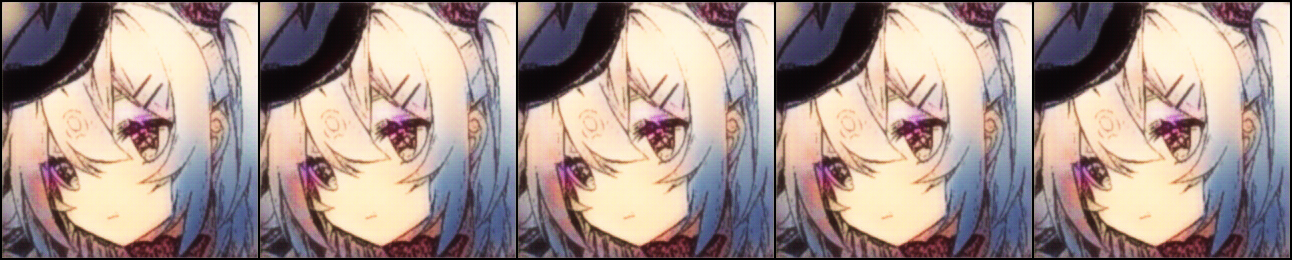

In [14]:
if DEVICE.type == 'cuda':
    item = val_ds[0]
    sketch, reference = item['sketch'][None].to(DEVICE), item['reference'][None].to(DEVICE)
    for i in range(5):
        colorizer.colorize(sketch, reference, i)
    torch.cuda.synchronize()
    elapsed = []
    for i in range(20):
        torch.cuda.synchronize()
        started = time.perf_counter()
        colorizer.colorize(sketch, reference, i)
        torch.cuda.synchronize()
        elapsed.append(time.perf_counter()-started)
    timing = dict(gpu=torch.cuda.get_device_name(0), batch_size=1, amp=AMP_ENABLED,
                  generator_calls_per_image=1, runs=len(elapsed),
                  seconds_mean=float(np.mean(elapsed)), seconds_std=float(np.std(elapsed)))
    (RUN/'results/timing.json').write_text(json.dumps(timing, indent=2))
    print(timing)
else:
    print('Bỏ qua benchmark GPU trên CPU.')

item = val_ds[0]
predictions = [colorizer.colorize(item['sketch'][None], item['reference'][None], seed)[0].cpu()
               for seed in cfg.SAMPLE_SEEDS]
grid = make_grid(torch.stack(predictions).add(1).div(2), nrow=len(cfg.SAMPLE_SEEDS))
save_image(grid, RUN/'previews/five_seeds.png')
display(TF.to_pil_image(grid))


## 15. Lưu kết quả và tiếp tục phiên Kaggle
- **Dữ liệu:** `DATA_ROOT` phải chỉ đúng thư mục chứa hai folder, hoặc chính file ZIP.
- **Hết VRAM:** giảm `BATCH_SIZE` và bắt đầu run mới. Giữ ảnh 256×256 theo protocol.
- **Phiên bị ngắt:** lưu Kaggle Version để giữ outputs. Phiên mới gắn output cũ và đặt `RESUME_PATH` đến `last.pt`.
- **Weights chưa tải được:** bật Internet cho VGG19/LPIPS; tắt chúng chỉ khi chủ động chạy ablation/debug.
- **Đánh giá cuối:** dùng `EXPORT_TEST_LIMIT=None`, chạy self-reference và cross-reference riêng.

Bàn giao `config.json`, `splits/`, `checkpoints/best.pt`, `results/`, `previews/` và ảnh trong `outputs/`.


## Nguồn tham khảo

- [Tài liệu thiết kế của dự án](../Reference-Based%20Anime%20Line-Art%20Colorization.md).
- [pix2pix: paper](https://arxiv.org/abs/1611.07004),
  [implementation chính thức](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix).
- [SCFT / augmented self-reference](https://arxiv.org/abs/2005.05207).
- [PyTorch AMP examples](https://docs.pytorch.org/docs/stable/notes/amp_examples.html).
- [torchvision VGG19](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg19.html).
- [LPIPS](https://github.com/richzhang/PerceptualSimilarity).

Code notebook là triển khai riêng theo kiến trúc pix2pix, bổ sung điều kiện reference theo đề cương;
không phải kết quả tái hiện đã xác nhận của SCFT hoặc AnimeDiffusion.

- [AnimeFaceColorization — dataset đã chọn](https://huggingface.co/datasets/ComputerVisionAnimeProject/AnimeFaceColorization).
- [Hugging Face: snapshot_download và local_dir](https://huggingface.co/docs/huggingface_hub/guides/download).
